In [1]:
'''

looking at how to implement sobel in this newest version
goal: remove cr, sats
only on highest snr data?
'''

'\n\nlooking at how to implement sobel in this newest version\ngoal: remove cr, sats\nonly on highest snr data?\n'

In [2]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp
import corner


Matplotlib is building the font cache; this may take a moment.


In [3]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [ ]:
#let's look at our top candidates and at a random candidates

In [4]:
concat = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat')

In [87]:
brightening = concat[concat['snr_local_brightening']>1.3]

In [13]:
sob = rff.add_sobel_ratio_fast(brightening)

/home/3155/rwe/review_findings_functions.py:1916: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["sobel_ratio"] = df.index.map(sobels)
/home/3155/rwe/review_findings_functions.py:1917: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["sobels_x"] = df.index.map(sobels_x)
/home/3155/rwe/review_findings_functions.py:1918: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: ht

In [14]:
sob

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,...,local_average_outside_dimming,height_dimming,FWHM_dimming,signal_local_dimming,central_point_dimming,quadrant,num_in_file_in_star,sobel_ratio,sobels_x,sobels_y
7,7,2,8,ztf_20221020163819_000640_zg_c10_x_0003.,3,both,465.183062,515.017927,74,524.0,...,325.550361,-25.022224,2.0,7.062065,491.0,3,1.0,0.804649,"[[-14.955811, 9.5967865, 17.212433, -5.444702,...","[[14.300354, -2.423172, -15.047241, -17.530975..."
217,217,12,30,ztf_20221020157697_000640_zi_c04_x_0017.,2,both,2430.638889,1963.027778,54,1974.0,...,187.448911,-22.788526,2.0,6.622256,2433.0,2,1.0,1.091052,"[[-14.195206, -26.899887, -16.85144, -8.847366...","[[-1.074295, 23.089401, 20.183105, 2.4376678, ..."
555,555,0,122,ztf_20221020294271_000449_zr_c13_x_0001.,4,both,171.744444,447.161111,28,458.0,...,100.141727,-22.903629,1.0,4.785774,193.0,4,1.0,0.878207,"[[-1.6703491, 4.087158, 26.466156, -9.065887, ...","[[1.4450684, 7.666565, 9.287689, 3.1645813, 12..."
1242,1242,5,12,ztf_20221020157697_000640_zi_c05_x_0000.,1,both,1558.134409,1897.122312,62,1906.0,...,160.898010,-22.429825,3.0,7.503358,1562.0,1,1.0,0.778748,"[[24.3992, 29.045898, 21.070892, 23.20903, 20....","[[-3.070221, -8.170898, -4.999298, 3.6976776, ..."
1361,1361,2,5,ztf_20221020141806_000686_zi_c02_x_0007.,1,both,2163.377955,2212.767730,91,2221.0,...,760.786812,-34.823433,2.0,8.009025,2168.0,1,1.0,0.864358,"[[0.2642212, -6.90094, -36.151825, -8.878952, ...","[[-12.9366455, -13.949524, -3.9151917, 3.77247..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46017,46017,17,42,ztf_20221020163819_000640_zg_c03_x_0011.,3,both,2299.535043,1623.786325,81,1633.0,...,197.937023,-40.736248,1.0,6.382495,2307.0,3,3.0,0.922684,"[[0.97161865, 8.343491, -31.365173, -30.582138...","[[-3.8189087, -9.362442, 4.292938, 19.184555, ..."
46052,46052,20,36,ztf_20221020141806_000686_zi_c14_x_0005.,4,both,1406.200758,697.712121,45,708.0,...,440.570468,180.484403,1.0,-13.434448,1410.0,4,49.0,10.653720,"[[11.363846, 67.98761, 57.737625, -41.28328, -...","[[-26.58641, -5.6138, 0.6970062, -5.2873077, 1..."
46053,46053,21,38,ztf_20221020141806_000686_zi_c14_x_0005.,4,both,1504.152299,698.365900,43,708.0,...,656.492086,-158.894674,107.0,149.623799,1539.0,4,49.0,14.250276,"[[63.90634, 64.87363, -26.034988, 14.481232, -...","[[-12.724884, 4.133087, 6.7844086, 2.156189, 9..."
46080,46080,48,86,ztf_20221020141806_000686_zi_c14_x_0005.,4,neg,64.083333,697.583333,12,708.0,...,251.050323,178.628510,1.0,-13.365198,81.0,4,49.0,11.739777,"[[30.517715, 61.895035, 38.120163, -16.508148,...","[[0.9564972, 2.5574799, 27.660324, 24.794617, ..."


In [136]:
def add_sobel_stuff(df, eff=False, central_row='', size=10):
    df['sobel_stdv_rat'+central_row+str(size)] = np.zeros(len(df))
    df['sobel_diffmax'+central_row+str(size)] = np.zeros(len(df))
    

    for i, row in df.iterrows():
        
        xnorm = row['sobels_x'+central_row+str(size)]
        ynorm = row['sobels_y'+central_row+str(size)]
        df['sobel_stdv_rat'+central_row+str(size)].loc[i] = np.std(xnorm)/np.std(ynorm)
        df['sobel_diffmax'+central_row+str(size)].loc[i] = np.max(xnorm)/np.max(ynorm)
        del xnorm, ynorm
        gc.collect()
                                                     
          
    return df

In [100]:
brightening

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,...,sobel_ratiocentral_point_brightening,sobels_xcentral_point_brightening,sobels_ycentral_point_brightening,sobel_ratiorow_from_nn,sobels_xrow_from_nn,sobels_yrow_from_nn,sobel_stdv_ratcentral_point_brightening,sobel_diffmaxcentral_point_brightening,sobel_stdv_rat,sobel_diffmax
7,7,2,8,ztf_20221020163819_000640_zg_c10_x_0003.,3,both,465.183062,515.017927,74,524.0,...,0.804649,"[[-14.955811, 9.5967865, 17.212433, -5.444702,...","[[14.300354, -2.423172, -15.047241, -17.530975...",0.804649,"[[-14.955811, 9.5967865, 17.212433, -5.444702,...","[[14.300354, -2.423172, -15.047241, -17.530975...",0.989758,0.804649,0.0,0.0
217,217,12,30,ztf_20221020157697_000640_zi_c04_x_0017.,2,both,2430.638889,1963.027778,54,1974.0,...,1.091052,"[[6.4685516, -9.944077, -5.3470154, 0.55651855...","[[-18.196915, -9.302567, -8.633392, -9.723938,...",1.091052,"[[-14.195206, -26.899887, -16.85144, -8.847366...","[[-1.074295, 23.089401, 20.183105, 2.4376678, ...",2.809696,1.091052,0.0,0.0
555,555,0,122,ztf_20221020294271_000449_zr_c13_x_0001.,4,both,171.744444,447.161111,28,458.0,...,0.878207,"[[-1.6703491, 4.087158, 26.466156, -9.065887, ...","[[1.4450684, 7.666565, 9.287689, 3.1645813, 12...",0.878207,"[[-1.6703491, 4.087158, 26.466156, -9.065887, ...","[[1.4450684, 7.666565, 9.287689, 3.1645813, 12...",1.061262,0.878207,0.0,0.0
1242,1242,5,12,ztf_20221020157697_000640_zi_c05_x_0000.,1,both,1558.134409,1897.122312,62,1906.0,...,0.778748,"[[24.3992, 29.045898, 21.070892, 23.20903, 20....","[[-3.070221, -8.170898, -4.999298, 3.6976776, ...",0.778748,"[[24.3992, 29.045898, 21.070892, 23.20903, 20....","[[-3.070221, -8.170898, -4.999298, 3.6976776, ...",0.951145,0.778748,0.0,0.0
1361,1361,2,5,ztf_20221020141806_000686_zi_c02_x_0007.,1,both,2163.377955,2212.767730,91,2221.0,...,0.864358,"[[0.2642212, -6.90094, -36.151825, -8.878952, ...","[[-12.9366455, -13.949524, -3.9151917, 3.77247...",0.864358,"[[0.2642212, -6.90094, -36.151825, -8.878952, ...","[[-12.9366455, -13.949524, -3.9151917, 3.77247...",2.847677,0.864358,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46017,46017,17,42,ztf_20221020163819_000640_zg_c03_x_0011.,3,both,2299.535043,1623.786325,81,1633.0,...,0.922684,"[[0.97161865, 8.343491, -31.365173, -30.582138...","[[-3.8189087, -9.362442, 4.292938, 19.184555, ...",0.922684,"[[0.97161865, 8.343491, -31.365173, -30.582138...","[[-3.8189087, -9.362442, 4.292938, 19.184555, ...",1.518615,0.922684,0.0,0.0
46052,46052,20,36,ztf_20221020141806_000686_zi_c14_x_0005.,4,both,1406.200758,697.712121,45,708.0,...,10.690885,"[[28.438232, 56.664276, 80.231415, -18.584503,...","[[2.7346191, 1.2328186, -2.9970398, -15.039032...",10.653720,"[[11.363846, 67.98761, 57.737625, -41.28328, -...","[[-26.58641, -5.6138, 0.6970062, -5.2873077, 1...",23.034147,10.690885,0.0,0.0
46053,46053,21,38,ztf_20221020141806_000686_zi_c14_x_0005.,4,both,1504.152299,698.365900,43,708.0,...,15.733885,"[[58.175293, 96.968445, -3.65625, -59.503433, ...","[[2.6938477, 9.97937, 5.1430664, 14.35112, 24....",14.250276,"[[63.90634, 64.87363, -26.034988, 14.481232, -...","[[-12.724884, 4.133087, 6.7844086, 2.156189, 9...",18.957552,15.733885,0.0,0.0
46080,46080,48,86,ztf_20221020141806_000686_zi_c14_x_0005.,4,neg,64.083333,697.583333,12,708.0,...,21.239042,"[[16.594635, 63.23375, 69.07065, -26.188705, -...","[[5.0134583, -7.5852203, 4.698059, 11.345139, ...",11.739777,"[[30.517715, 61.895035, 38.120163, -16.508148,...","[[0.9564972, 2.5574799, 27.660324, 24.794617, ...",14.279093,21.239042,0.0,0.0


In [138]:
brightening = add_sobel_stuff(brightening, central_row='central_point_brightening', size=3)

/tmp/ipykernel_1266/509364057.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sobel_stdv_rat'+central_row+str(size)].loc[i] = np.std(xnorm)/np.std(ynorm)
/tmp/ipykernel_1266/509364057.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sobel_diffmax'+central_row+str(size)].loc[i] = np.max(xnorm)/np.max(ynorm)


In [101]:
brightening = add_sobel_stuff(brightening, central_row='row_from_nn')

/tmp/ipykernel_1266/2896707799.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sobel_stdv_rat'+central_row].loc[i] = np.std(xnorm)/np.std(ynorm)
/tmp/ipykernel_1266/2896707799.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sobel_diffmax'+central_row].loc[i] = np.max(xnorm)/np.max(ynorm)


In [104]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [106]:
def add_sobel_ratio_fast(df, central_row, direcname='1020', size=10):
    """
    returns the dataframe with a new column of sobel ratios
    see get_sobel_ratio(stamp)
    """
    sobels = {}
    sobels_x = {}
    sobels_y = {}
    # i=0
    for filename, group in df.groupby('filename'):     
        fpath = (
            "/lustre/lrspec/ZTF_data/2022/"
            + direcname
            + "/"
        )
        path = fpath + filename+'fits.fz'
        with fits.open(path) as hdul:
            for idx in group.index:
                # quad = int(df.loc[idx]["quad"])
                
                stamp, bg = rff.get_stamp_from_hdul(hdul, idx, direcname, df, norm=False, central_row=central_row, size=size)
                sobel, x, y = rff.get_sobel_ratio(stamp-bg)
                # print(sobel)
                # print(np.shape(x))
                # print(np.shape(y))
                sobels[idx] = sobel
                sobels_x[idx] = x
                sobels_y[idx] = y
                # i+=1
    df["sobel_ratio"+central_row+str(size)] = df.index.map(sobels)
    df["sobels_x"+central_row+str(size)] = df.index.map(sobels_x)
    df["sobels_y"+central_row+str(size)] = df.index.map(sobels_y)
    return df


In [90]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [92]:
brightening = brightening[brightening['row_from_nn']>20]

In [110]:
brightening = add_sobel_ratio_fast(brightening, central_row='central_point_brightening', direcname='1020', size=5)

In [97]:
brightening = add_sobel_ratio_fast(brightening,  direcname='1020', central_row='row_from_nn')

In [51]:
rff.inspect_df_w_stamp_color?

Signature:
rff.inspect_df_w_stamp_color(
    df,
    imgsize=10,
    star=False,
    clim=None,
    plot='stamp',
    norm=False,
    titlecol=[],
    twodec=False,
)
Docstring:
plots the stamps corresponding to detections in a dataframe
no limit, so put in df[:100] or something probably to save time
File:      ~/rwe/review_findings_functions.py
Type:      function

In [53]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [60]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [108]:
brightening

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,...,sobels_yrow_from_nn,sobel_stdv_ratcentral_point_brightening,sobel_diffmaxcentral_point_brightening,sobel_stdv_rat,sobel_diffmax,sobel_stdv_ratrow_from_nn,sobel_diffmaxrow_from_nn,sobel_ratiocentral_point_brightening3,sobels_xcentral_point_brightening3,sobels_ycentral_point_brightening3
7,7,2,8,ztf_20221020163819_000640_zg_c10_x_0003.,3,both,465.183062,515.017927,74,524.0,...,"[[14.300354, -2.423172, -15.047241, -17.530975...",0.989758,0.804649,0.0,0.0,0.989758,0.804649,0.470798,"[[82.63899, 219.78015, 350.81506, 102.862335, ...","[[-12.967575, 10.91629, 37.26364, 32.747498, 3..."
217,217,12,30,ztf_20221020157697_000640_zi_c04_x_0017.,2,both,2430.638889,1963.027778,54,1974.0,...,"[[-1.074295, 23.089401, 20.183105, 2.4376678, ...",2.809696,1.091052,0.0,0.0,2.763812,1.091052,1.091052,"[[8.865173, 54.11763, 227.20134, 196.2019, -19...","[[10.098511, 0.052261353, 9.662735, 11.752869,..."
555,555,0,122,ztf_20221020294271_000449_zr_c13_x_0001.,4,both,171.744444,447.161111,28,458.0,...,"[[1.4450684, 7.666565, 9.287689, 3.1645813, 12...",1.061262,0.878207,0.0,0.0,1.061262,0.878207,0.878207,"[[-6.3073883, 46.367004, 160.45302, 94.34177, ...","[[-7.3405914, -7.0466614, -12.732559, -10.2298..."
1242,1242,5,12,ztf_20221020157697_000640_zi_c05_x_0000.,1,both,1558.134409,1897.122312,62,1906.0,...,"[[-3.070221, -8.170898, -4.999298, 3.6976776, ...",0.951145,0.778748,0.0,0.0,0.951145,0.778748,0.778748,"[[111.24376, 383.70752, 63.43193, -313.5763, -...","[[10.888718, -6.9758606, -23.220078, -9.05397,..."
1361,1361,2,5,ztf_20221020141806_000686_zi_c02_x_0007.,1,both,2163.377955,2212.767730,91,2221.0,...,"[[-12.9366455, -13.949524, -3.9151917, 3.77247...",2.847677,0.864358,0.0,0.0,2.847677,0.864358,0.601081,"[[-15.6384735, 62.24109, 842.4487, 1116.5365, ...","[[37.439224, -1.3881531, -29.533981, -42.40878..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46017,46017,17,42,ztf_20221020163819_000640_zg_c03_x_0011.,3,both,2299.535043,1623.786325,81,1633.0,...,"[[-3.8189087, -9.362442, 4.292938, 19.184555, ...",1.518615,0.922684,0.0,0.0,1.518615,0.922684,0.922684,"[[51.792786, 103.980515, 170.42429, 112.14386,...","[[-18.72284, -9.368851, -8.763184, -14.023407,..."
46052,46052,20,36,ztf_20221020141806_000686_zi_c14_x_0005.,4,both,1406.200758,697.712121,45,708.0,...,"[[-26.58641, -5.6138, 0.6970062, -5.2873077, 1...",23.034147,10.690885,0.0,0.0,17.204575,10.653720,19.092361,"[[-8.796249, 87.713974, 654.15564, 1906.5012, ...","[[4.358597, 10.654556, 9.810211, -46.51654, -8..."
46053,46053,21,38,ztf_20221020141806_000686_zi_c14_x_0005.,4,both,1504.152299,698.365900,43,708.0,...,"[[-12.724884, 4.133087, 6.7844086, 2.156189, 9...",18.957552,15.733885,0.0,0.0,12.709288,14.250276,23.130087,"[[63.32103, 406.1427, 1463.5691, 619.1738, -12...","[[-35.827164, -47.16478, -17.302887, 37.572235..."
46080,46080,48,86,ztf_20221020141806_000686_zi_c14_x_0005.,4,neg,64.083333,697.583333,12,708.0,...,"[[0.9564972, 2.5574799, 27.660324, 24.794617, ...",14.279093,21.239042,0.0,0.0,11.484085,11.739777,25.115046,"[[-33.38719, 74.19495, 669.68665, 963.17535, -...","[[-6.384262, 12.528412, 2.5019531, -2.928299, ..."


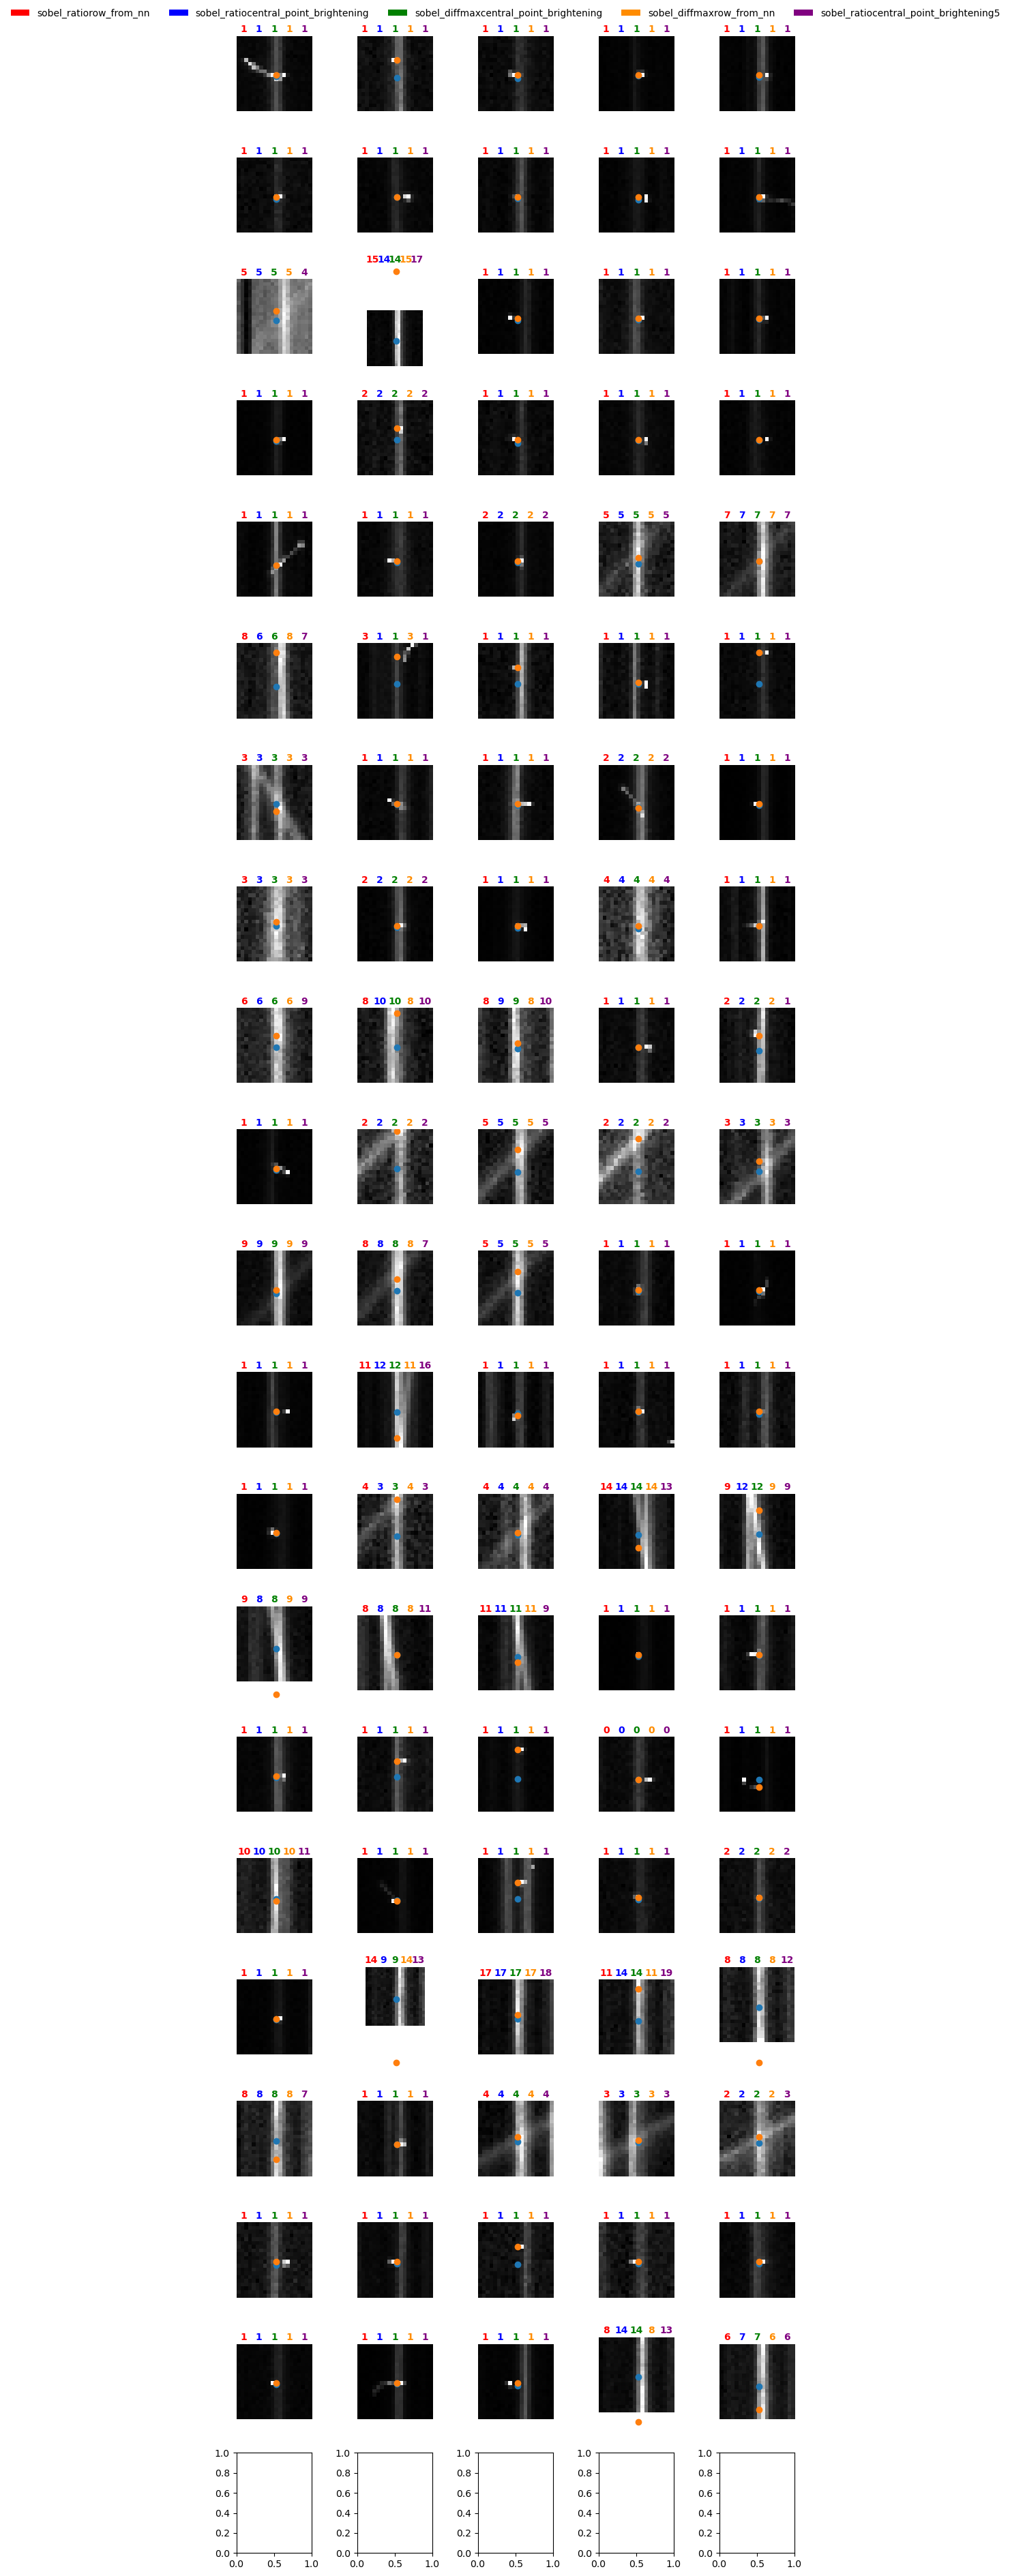

In [112]:
rff.inspect_df_w_stamp_color(brightening[:100], plot_centers=True,star=False,titlecol=['sobel_ratiorow_from_nn','sobel_ratiocentral_point_brightening', 'sobel_diffmaxcentral_point_brightening','sobel_diffmaxrow_from_nn', 'sobel_ratiocentral_point_brightening5'])

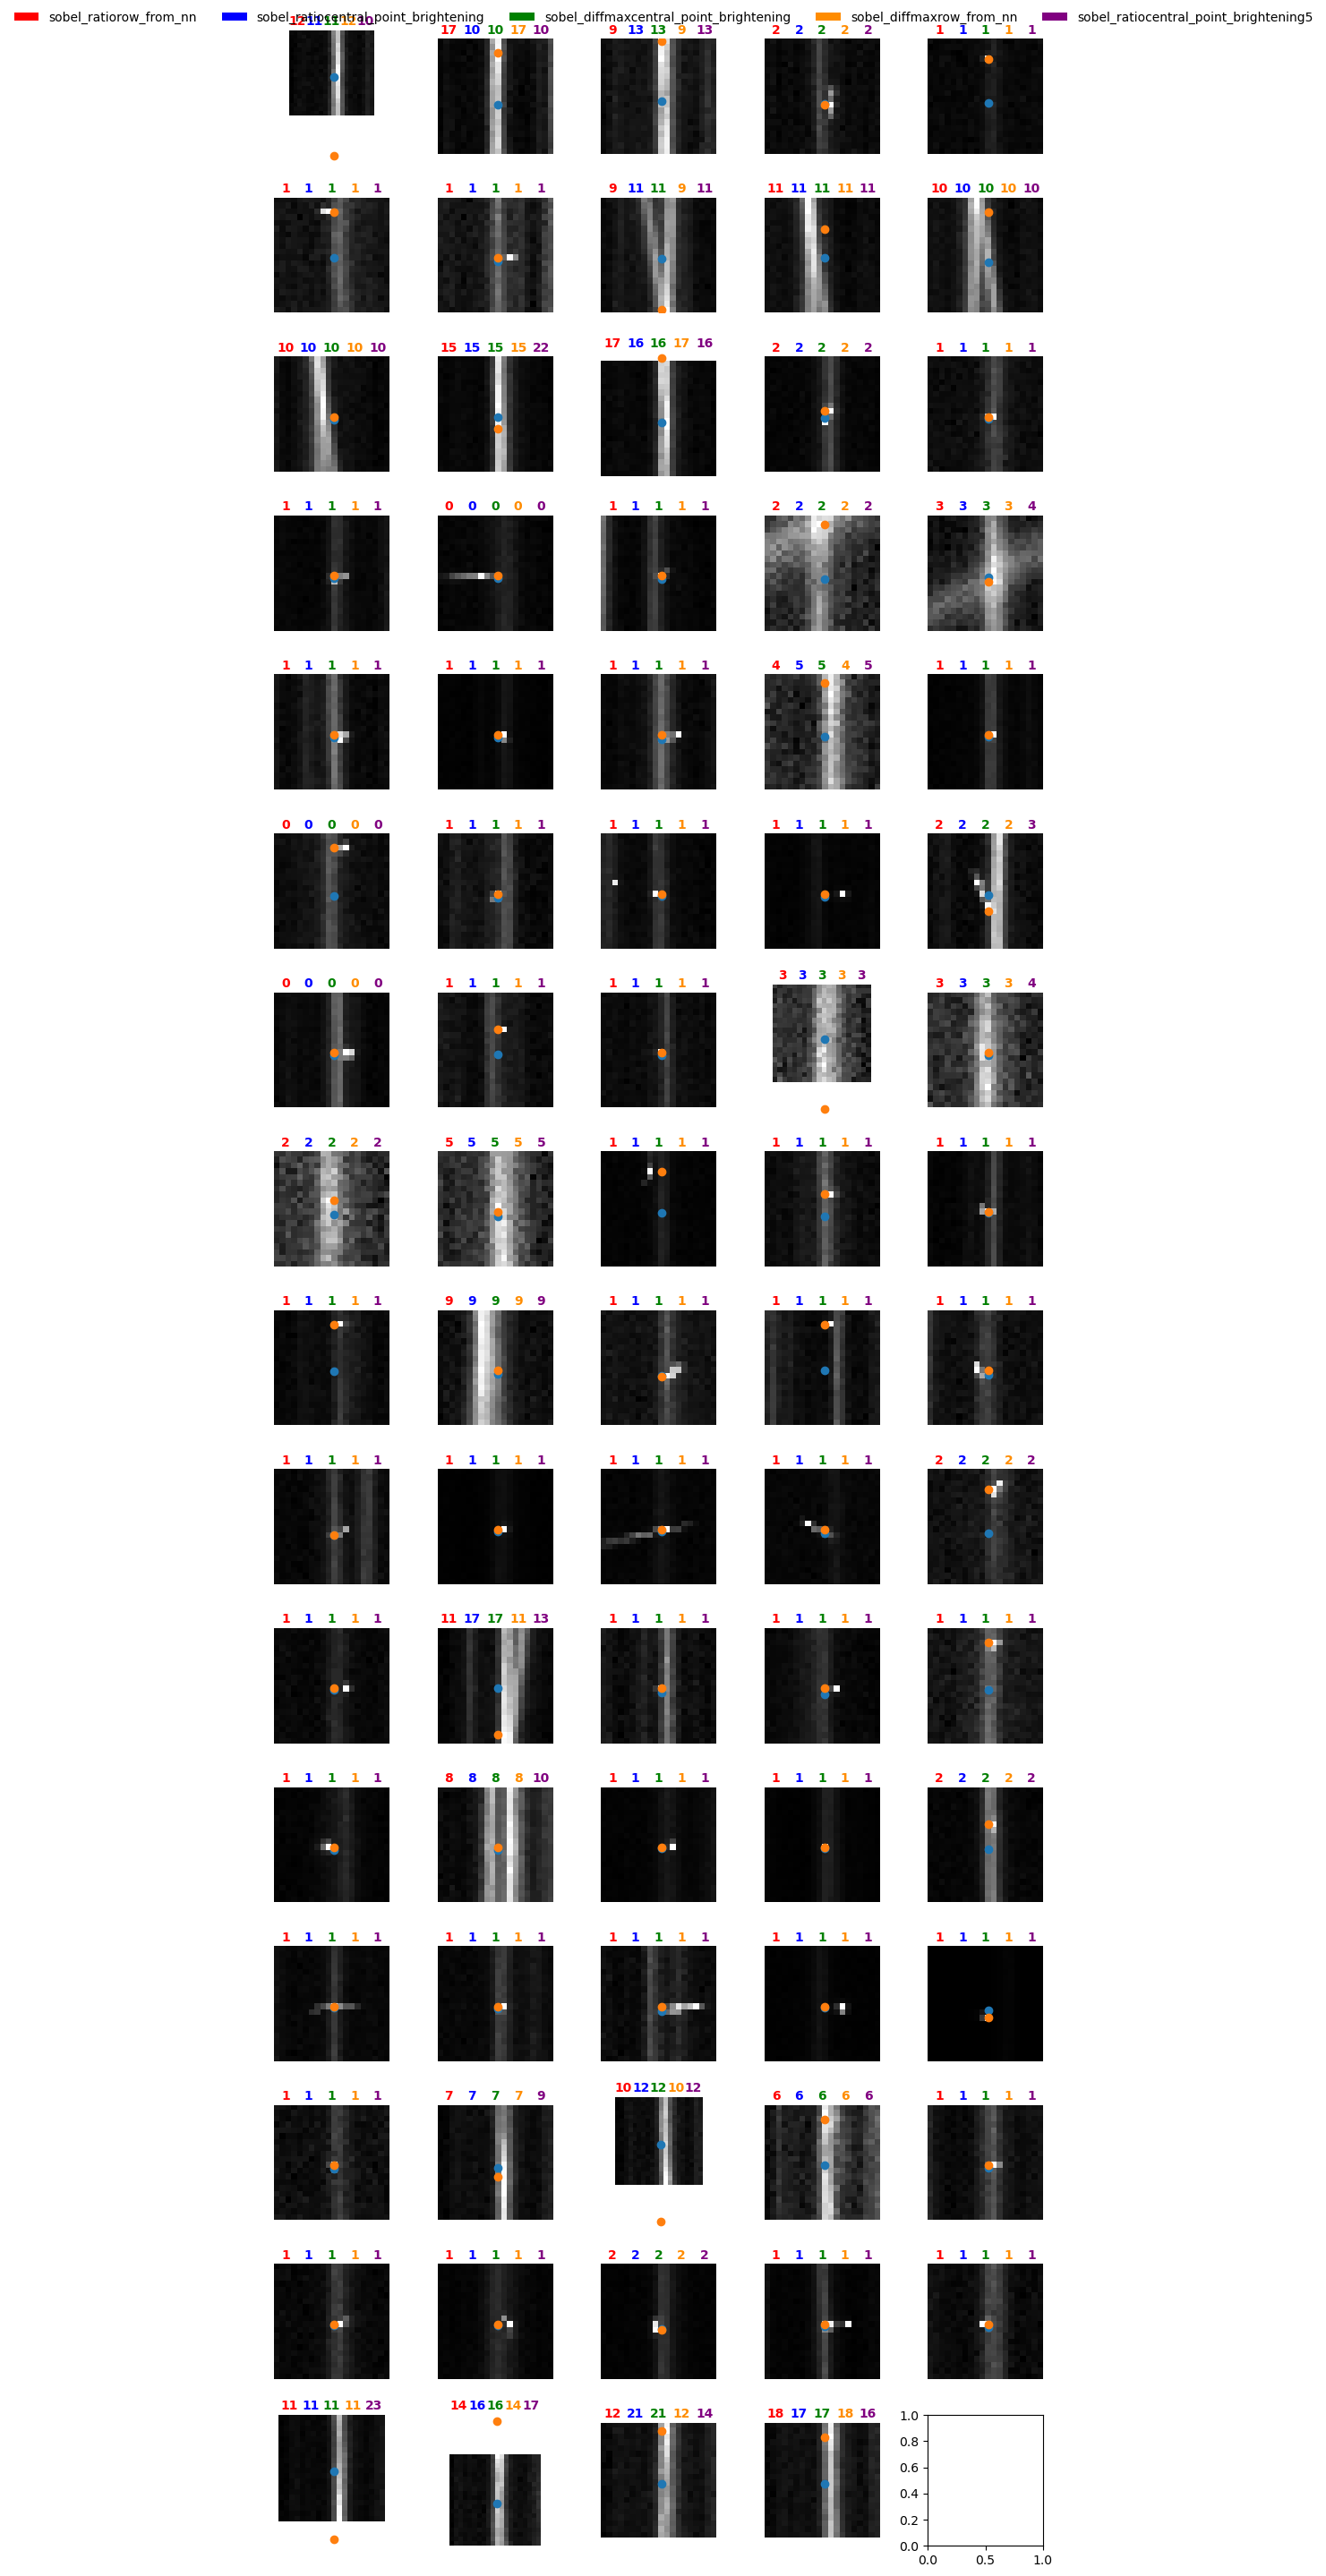

In [111]:
rff.inspect_df_w_stamp_color(brightening[100:200], plot_centers=True,star=False,titlecol=['sobel_ratiorow_from_nn','sobel_ratiocentral_point_brightening', 'sobel_diffmaxcentral_point_brightening','sobel_diffmaxrow_from_nn', 'sobel_ratiocentral_point_brightening5'])

(array([166.,  12.,   4.,   0.,   0.,   0.,   0.,   0.,   0.,   1.]),
 array([ -5.23437643,  42.6869739 ,  90.60832423, 138.52967456,
        186.45102489, 234.37237522, 282.29372555, 330.21507588,
        378.13642621, 426.05777654, 473.97912687]),
 <BarContainer object of 10 artists>)

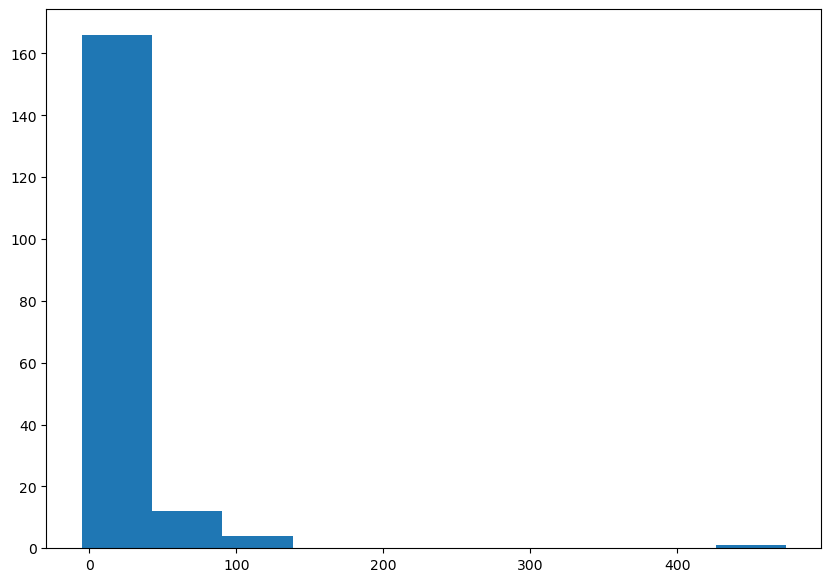

In [50]:
plt.hist(brightening['sobel_diffmaxcentral_point_brightening']-brightening['sobel_diffmax'])

(array([166.,  12.,   4.,   0.,   0.,   0.,   0.,   0.,   0.,   1.]),
 array([ -5.23437643,  42.6869739 ,  90.60832423, 138.52967456,
        186.45102489, 234.37237522, 282.29372555, 330.21507588,
        378.13642621, 426.05777654, 473.97912687]),
 <BarContainer object of 10 artists>)

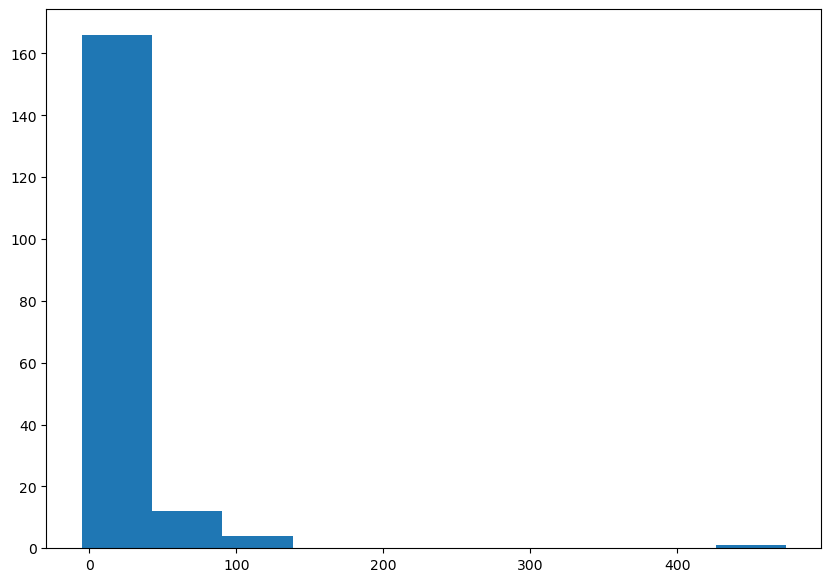

In [44]:
plt.hist(brightening['sobel_ratiocentral_point_brightening']-brightening['sobel_ratio'])

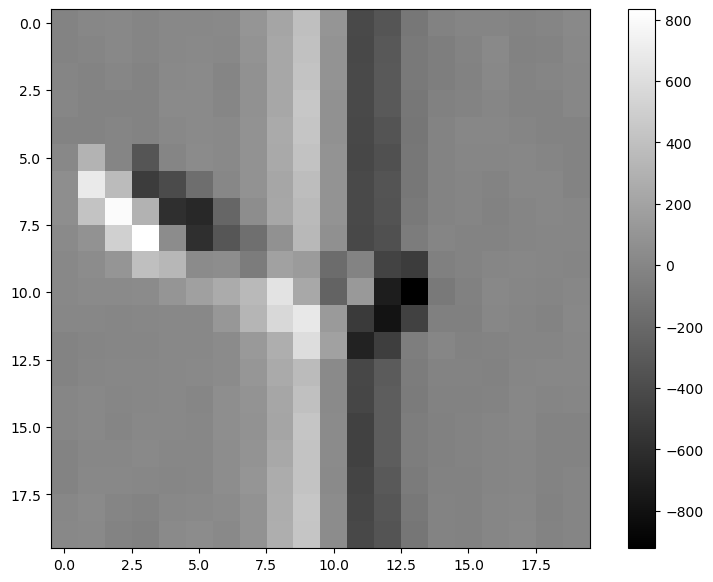

In [75]:
plt.imshow(brightening.iloc[0]['sobels_x'])
plt.colorbar()

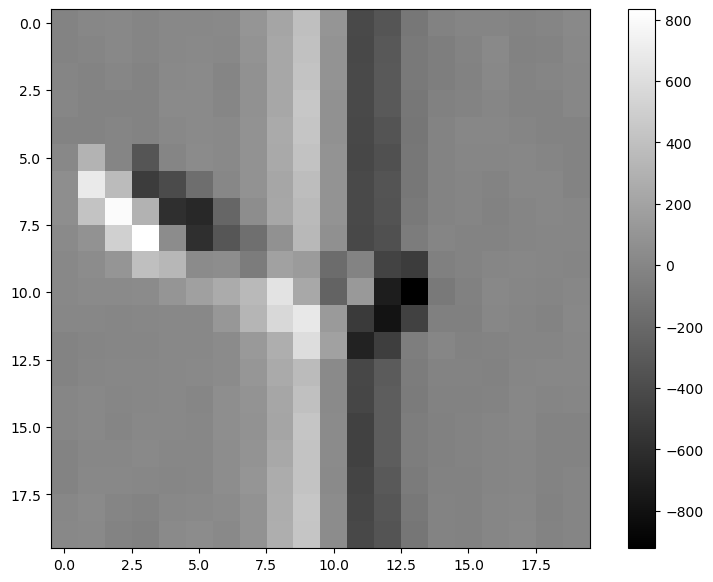

In [76]:
plt.imshow(brightening.iloc[0]['sobels_xcentral_point_brightening'])
plt.colorbar()

In [122]:
np.arange?

Docstring:
arange([start,] stop[, step,], dtype=None, *, like=None)

Return evenly spaced values within a given interval.

``arange`` can be called with a varying number of positional arguments:

* ``arange(stop)``: Values are generated within the half-open interval
  ``[0, stop)`` (in other words, the interval including `start` but
  excluding `stop`).
* ``arange(start, stop)``: Values are generated within the half-open
  interval ``[start, stop)``.
* ``arange(start, stop, step)`` Values are generated within the half-open
  interval ``[start, stop)``, with spacing between values given by
  ``step``.

For integer arguments the function is roughly equivalent to the Python
built-in :py:class:`range`, but returns an ndarray rather than a ``range``
instance.

When using a non-integer step, such as 0.1, it is often better to use
`numpy.linspace`.

See the Warning sections below for more information.

Parameters
----------
start : integer or real, optional
    Start of interval.  The interva

In [128]:
brightening.iloc[0]

Unnamed: 0.2                                                                               7
Unnamed: 0.1                                                                               2
Unnamed: 0                                                                                 8
filename                                            ztf_20221020163819_000640_zg_c10_x_0003.
quad                                                                                       3
type                                                                                    both
row_from_nn                                                                       465.183062
col_from_nn                                                                       515.017927
detection_size                                                                            74
closest_x                                                                              524.0
closest_y                                                             

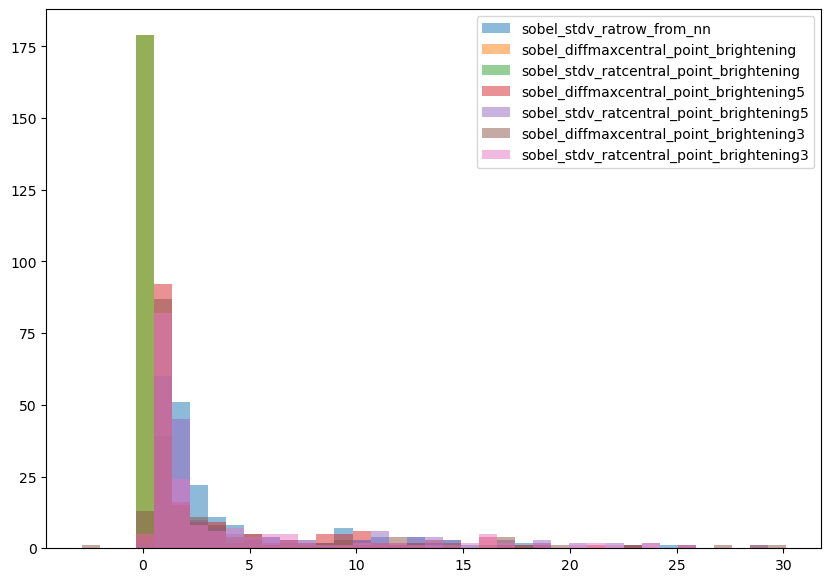

In [140]:
bins = np.linspace(np.min(brightening['sobel_ratiocentral_point_brightening3']), np.max(brightening['sobel_ratiocentral_point_brightening3']), 40)
# plt.hist(brightening['sobel_ratiocentral_point_brightening5'], label='5',bins=bins, alpha=.5)
# plt.hist(brightening['sobel_ratiocentral_point_brightening3'], label='3', bins=bins, alpha=.5)
# plt.hist(brightening['sobel_ratiocentral_point_brightening'], label='10', bins=bins, alpha=.5)
# plt.hist(brightening['sobel_ratiorow_from_nn'], label='nn', bins=bins, alpha=.5)
plt.hist(brightening['sobel_stdv_ratrow_from_nn'], label='sobel_stdv_ratrow_from_nn', bins=bins, alpha=.5)
plt.hist(brightening['sobel_diffmaxcentral_point_brightening'], label='sobel_diffmaxcentral_point_brightening', bins=bins, alpha=.5)
plt.hist(brightening['sobel_stdv_ratcentral_point_brightening'], label='sobel_stdv_ratcentral_point_brightening', bins=bins, alpha=.5)
plt.hist(brightening['sobel_diffmaxcentral_point_brightening5'], label='sobel_diffmaxcentral_point_brightening5', bins=bins, alpha=.5)
plt.hist(brightening['sobel_stdv_ratcentral_point_brightening5'], label='sobel_stdv_ratcentral_point_brightening5', bins=bins, alpha=.5)
plt.hist(brightening['sobel_diffmaxcentral_point_brightening3'], label='sobel_diffmaxcentral_point_brightening3', bins=bins, alpha=.5)
plt.hist(brightening['sobel_stdv_ratcentral_point_brightening3'], label='sobel_stdv_ratcentral_point_brightening3', bins=bins, alpha=.5)

plt.legend()

In [147]:
len(brightening[brightening['sobel_ratiocentral_point_brightening5']<2])

113

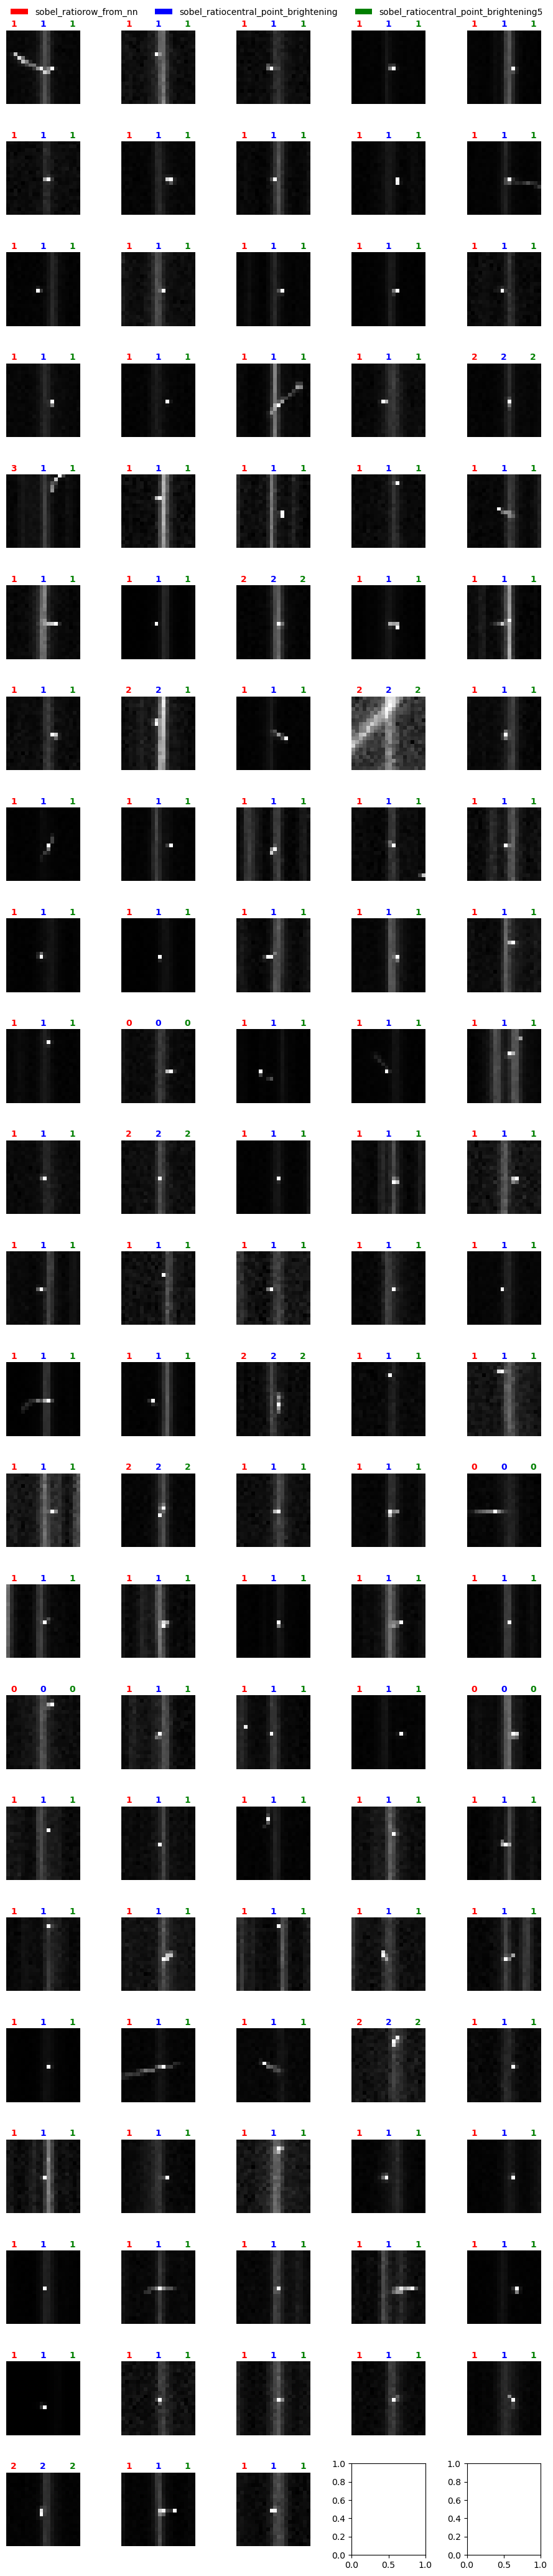

In [148]:
rff.inspect_df_w_stamp_color(brightening[brightening['sobel_ratiocentral_point_brightening5']<2], plot_centers=False,star=False,titlecol=['sobel_ratiorow_from_nn','sobel_ratiocentral_point_brightening', 'sobel_ratiocentral_point_brightening5'])

In [151]:
len(brightening)

179

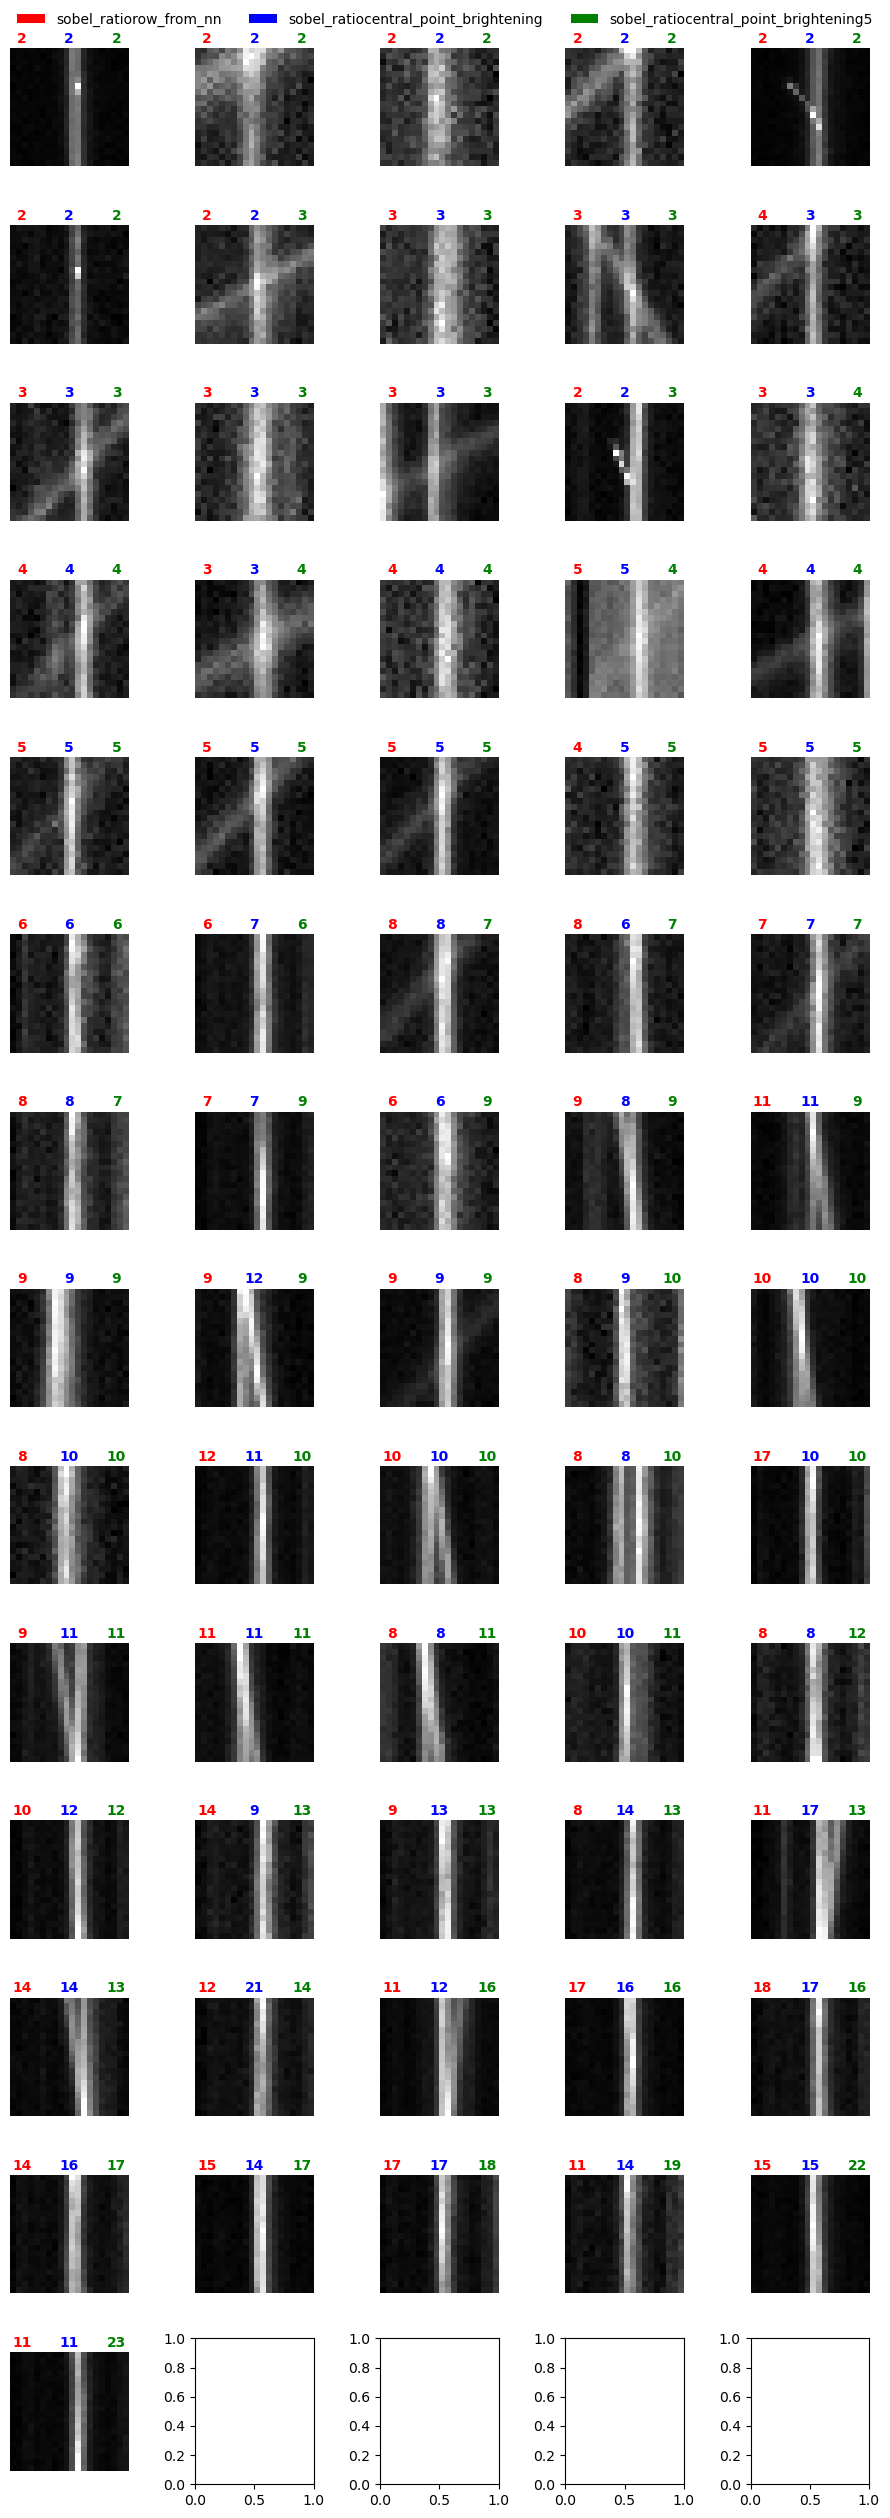

In [150]:
rff.inspect_df_w_stamp_color(brightening[brightening['sobel_ratiocentral_point_brightening5']>=2].sort_values('sobel_ratiocentral_point_brightening5'), plot_centers=False,star=False,titlecol=['sobel_ratiorow_from_nn','sobel_ratiocentral_point_brightening', 'sobel_ratiocentral_point_brightening5'])

In [152]:
#TODO:

#plot 100 snr < something
#and 100 snr> something and fails sobel criteria
#and 100 snr> something and meets sobel criteria

#then estimate the contamination
newconcat = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat')

In [154]:
newconcat = newconcat[newconcat['col_from_nn']>10]

In [157]:
newbrightening = newconcat[newconcat['snr_local_brightening']>1]

In [163]:
add_sobel_ratio_fast?

Signature: add_sobel_ratio_fast(df, central_row, direcname='1020', size=10)
Docstring:
returns the dataframe with a new column of sobel ratios
see get_sobel_ratio(stamp)
File:      /tmp/ipykernel_1266/1650212483.py
Type:      function

In [165]:
newbrightening = newbrightening[newbrightening['central_point_brightening']>20]

In [166]:
newbrightening

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,...,snr_global_dimming,noise_local_dimming,noise_global_dimming,local_average_outside_dimming,height_dimming,FWHM_dimming,signal_local_dimming,central_point_dimming,quadrant,num_in_file_in_star
51,51,5,10,ztf_20221020154120_000640_zi_c11_x_0012.,4,both,1511.922323,815.613122,53,825.0,...,0.273819,15.774200,17.770920,344.338891,-23.678064,1.0,4.866011,1538.0,4,1.0
120,120,2,8,ztf_20221020163819_000640_zg_c10_x_0003.,3,both,465.183062,515.017927,74,524.0,...,0.473298,13.694632,14.920984,325.550361,-25.022224,2.0,7.062065,491.0,3,1.0
252,252,1,5,ztf_20221020157697_000640_zi_c12_x_0000.,1,both,2562.299905,877.769116,106,889.0,...,0.258047,15.575492,27.551938,382.675806,-50.547938,1.0,7.109707,2563.0,1,1.0
254,254,3,0,ztf_20221020157697_000640_zi_c12_x_0000.,1,both,649.444712,1409.731370,79,1421.0,...,0.414287,17.872526,18.885323,477.767923,-34.014383,2.0,7.823950,676.0,1,1.0
752,752,12,30,ztf_20221020157697_000640_zi_c04_x_0017.,2,both,2430.638889,1963.027778,54,1974.0,...,0.538043,10.843917,12.308042,187.448911,-22.788526,2.0,6.622256,2433.0,2,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115550,115550,3,63,ztf_20221020148032_000686_zg_c12_x_0026.,1,both,1819.201128,290.374687,59,302.0,...,0.397891,10.725156,12.158258,169.809099,-23.402971,1.0,4.837662,1814.0,1,1.0
115608,115608,61,45,ztf_20221020148032_000686_zg_c12_x_0026.,1,pos,1451.222222,2609.000000,9,2620.0,...,0.167488,13.338188,14.675573,282.933268,-6.041666,1.0,2.457980,1468.0,1,3.0
115748,115748,54,22,ztf_20221020163819_000640_zg_c09_x_0020.,4,pos,889.000000,2575.000000,15,2584.0,...,0.325772,20.173875,21.994931,463.466562,-33.665964,2.0,7.165337,906.0,4,1.0
115826,115826,46,20,ztf_20221020148032_000686_zg_c14_x_0016.,3,pos,1388.750000,2864.166667,12,2874.0,...,0.217833,18.582238,20.647186,544.280722,-20.228842,1.0,4.497648,1407.0,3,4.0


In [167]:
newbrightening = add_sobel_ratio_fast(newbrightening, central_row='central_point_brightening', size=5)

/tmp/ipykernel_1266/1650212483.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["sobel_ratio"+central_row+str(size)] = df.index.map(sobels)
/tmp/ipykernel_1266/1650212483.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["sobels_x"+central_row+str(size)] = df.index.map(sobels_x)
/tmp/ipykernel_1266/1650212483.py:32: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documenta

In [169]:
newbrightening

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,...,local_average_outside_dimming,height_dimming,FWHM_dimming,signal_local_dimming,central_point_dimming,quadrant,num_in_file_in_star,sobel_ratiocentral_point_brightening5,sobels_xcentral_point_brightening5,sobels_ycentral_point_brightening5
51,51,5,10,ztf_20221020154120_000640_zi_c11_x_0012.,4,both,1511.922323,815.613122,53,825.0,...,344.338891,-23.678064,1.0,4.866011,1538.0,4,1.0,1.027751,"[[35.49907, 7.0372467, 48.015366, 413.5868, 55...","[[7.603012, -17.277786, -33.199966, -30.088425..."
120,120,2,8,ztf_20221020163819_000640_zg_c10_x_0003.,3,both,465.183062,515.017927,74,524.0,...,325.550361,-25.022224,2.0,7.062065,491.0,3,1.0,0.656194,"[[23.885605, 14.508545, 69.82497, 232.10411, 4...","[[15.574142, 17.46701, 25.155136, 28.429245, 1..."
252,252,1,5,ztf_20221020157697_000640_zi_c12_x_0000.,1,both,2562.299905,877.769116,106,889.0,...,382.675806,-50.547938,1.0,7.109707,2563.0,1,1.0,0.978361,"[[-18.603638, 5.131851, 92.10524, 242.38719, 3...","[[8.156677, 22.309158, 2.1102753, -31.202347, ..."
254,254,3,0,ztf_20221020157697_000640_zi_c12_x_0000.,1,both,649.444712,1409.731370,79,1421.0,...,477.767923,-34.014383,2.0,7.823950,676.0,1,1.0,1.304655,"[[-198.14687, -259.50598, -86.45073, 52.952454...","[[-10.038773, 2.8083038, -4.811264, 1.9429016,..."
752,752,12,30,ztf_20221020157697_000640_zi_c04_x_0017.,2,both,2430.638889,1963.027778,54,1974.0,...,187.448911,-22.788526,2.0,6.622256,2433.0,2,1.0,1.091052,"[[6.528702, 56.902634, 32.72484, 78.093506, 25...","[[1.8666534, 2.195755, -0.4577179, 2.1023254, ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115550,115550,3,63,ztf_20221020148032_000686_zg_c12_x_0026.,1,both,1819.201128,290.374687,59,302.0,...,169.809099,-23.402971,1.0,4.837662,1814.0,1,1.0,1.802981,"[[1.8437958, -11.033264, 6.9278107, 95.116394,...","[[-11.689529, -21.443024, -22.254654, -25.6877..."
115608,115608,61,45,ztf_20221020148032_000686_zg_c12_x_0026.,1,pos,1451.222222,2609.000000,9,2620.0,...,282.933268,-6.041666,1.0,2.457980,1468.0,1,3.0,8.467044,"[[-44.9946, -2.7238617, 74.75563, 311.3058, 48...","[[-14.733734, 17.75148, 16.450485, -6.656601, ..."
115748,115748,54,22,ztf_20221020163819_000640_zg_c09_x_0020.,4,pos,889.000000,2575.000000,15,2584.0,...,463.466562,-33.665964,2.0,7.165337,906.0,4,1.0,15.371267,"[[47.274002, 71.380936, 133.56863, 512.8344, 5...","[[23.15358, 23.404648, 23.520844, 19.771408, 1..."
115826,115826,46,20,ztf_20221020148032_000686_zg_c14_x_0016.,3,pos,1388.750000,2864.166667,12,2874.0,...,544.280722,-20.228842,1.0,4.497648,1407.0,3,4.0,15.051464,"[[2.88768, 57.797348, 204.86691, 604.4049, 791...","[[-8.818069, -7.336838, 4.8522644, -28.219528,..."


In [170]:
newbrightening.to_csv('/lustre/lrspec/ZTF_data/newbrightening')



In [171]:
rff.inspect_df_w_stamp_color(newbrightening[newbrightening['sobel_ratiocentral_point_brightening5']<=2].sort_values('sobel_ratiocentral_point_brightening5'), plot_centers=False,star=False,titlecol=['sobel_ratiocentral_point_brightening5', 'snr_local_brightening'], twodec=True)

In [172]:
#and then a random 100 where it is greater than 2
sample = newbrightening[newbrightening['sobel_ratiocentral_point_brightening5']>2].sample(n=100, random_state=42)

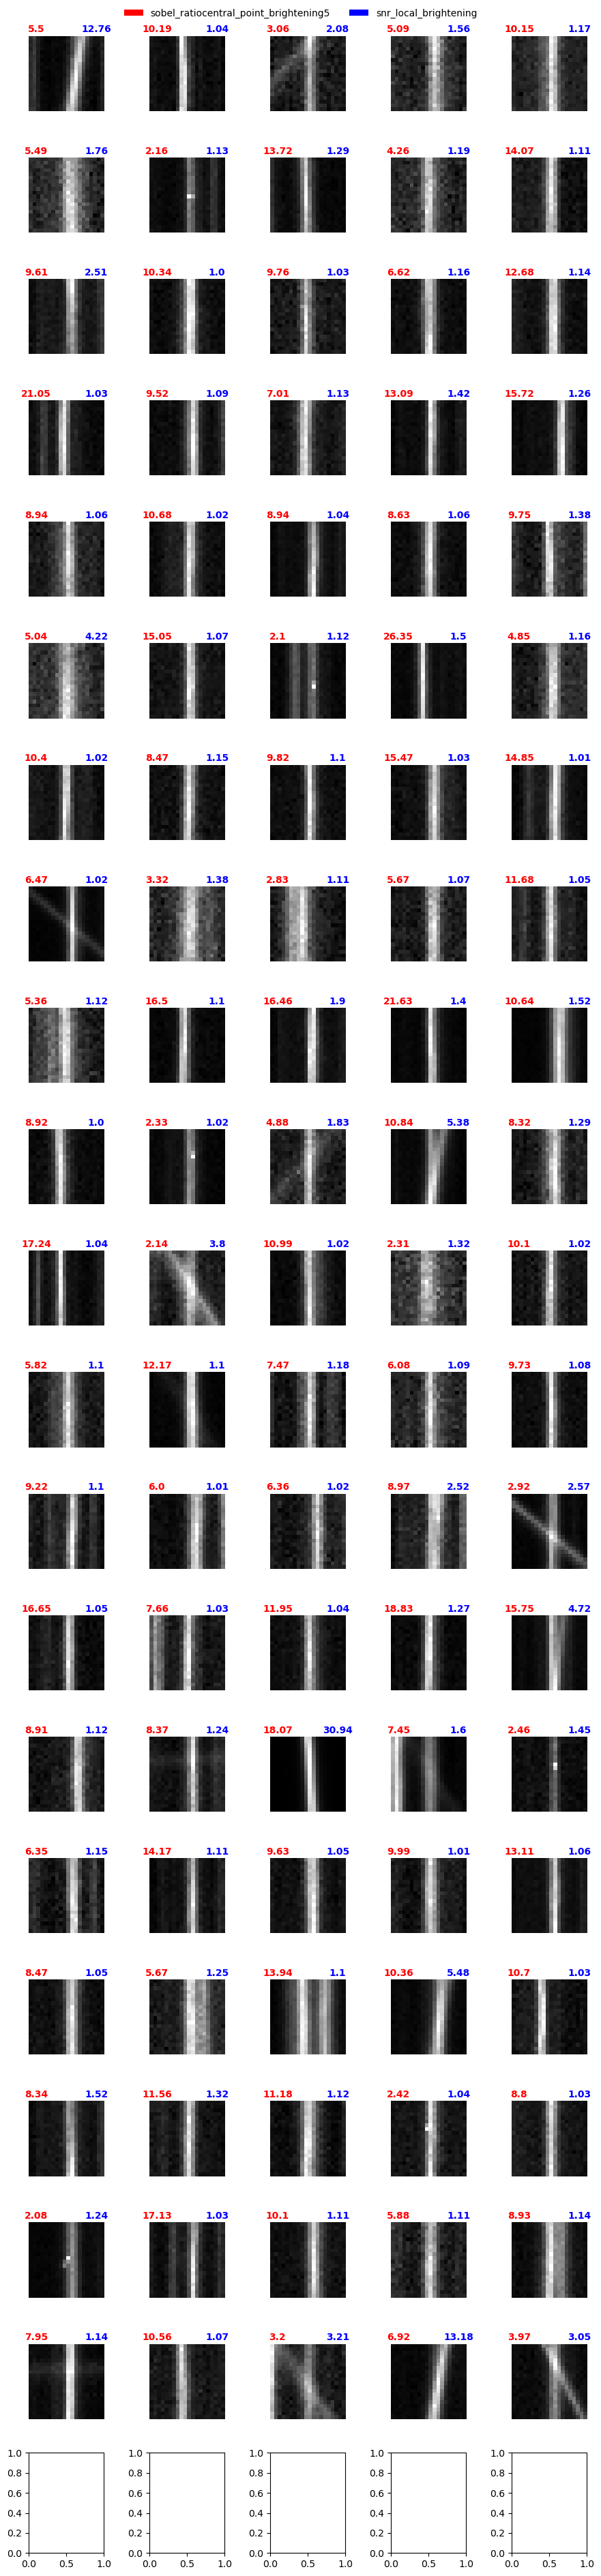

In [173]:
rff.inspect_df_w_stamp_color(sample, plot_centers=False,star=False,titlecol=['sobel_ratiocentral_point_brightening5', 'snr_local_brightening'], twodec=True)

(array([902.,  68.,  14.,   8.,   7.,  14.,  17.,  12.,   4.,   9.]),
 array([ 1. ,  7.2, 13.4, 19.6, 25.8, 32. , 38.2, 44.4, 50.6, 56.8, 63. ]),
 <BarContainer object of 10 artists>)

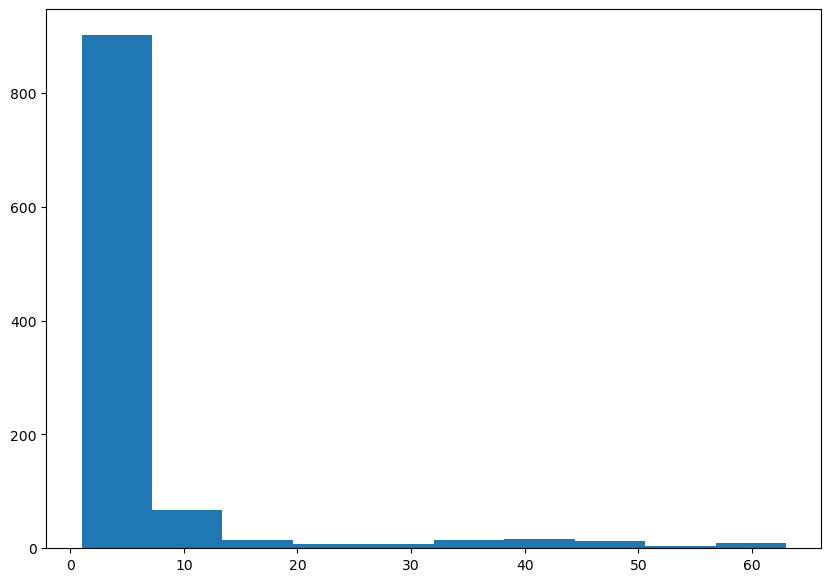

In [177]:
plt.hist(newbrightening['num_in_file_in_star'])

In [174]:
#and then a random 100 where the snr is less than 1
lowsnrsample = concat[concat['snr_local_brightening']<=1].sample(n=100, random_state=42)

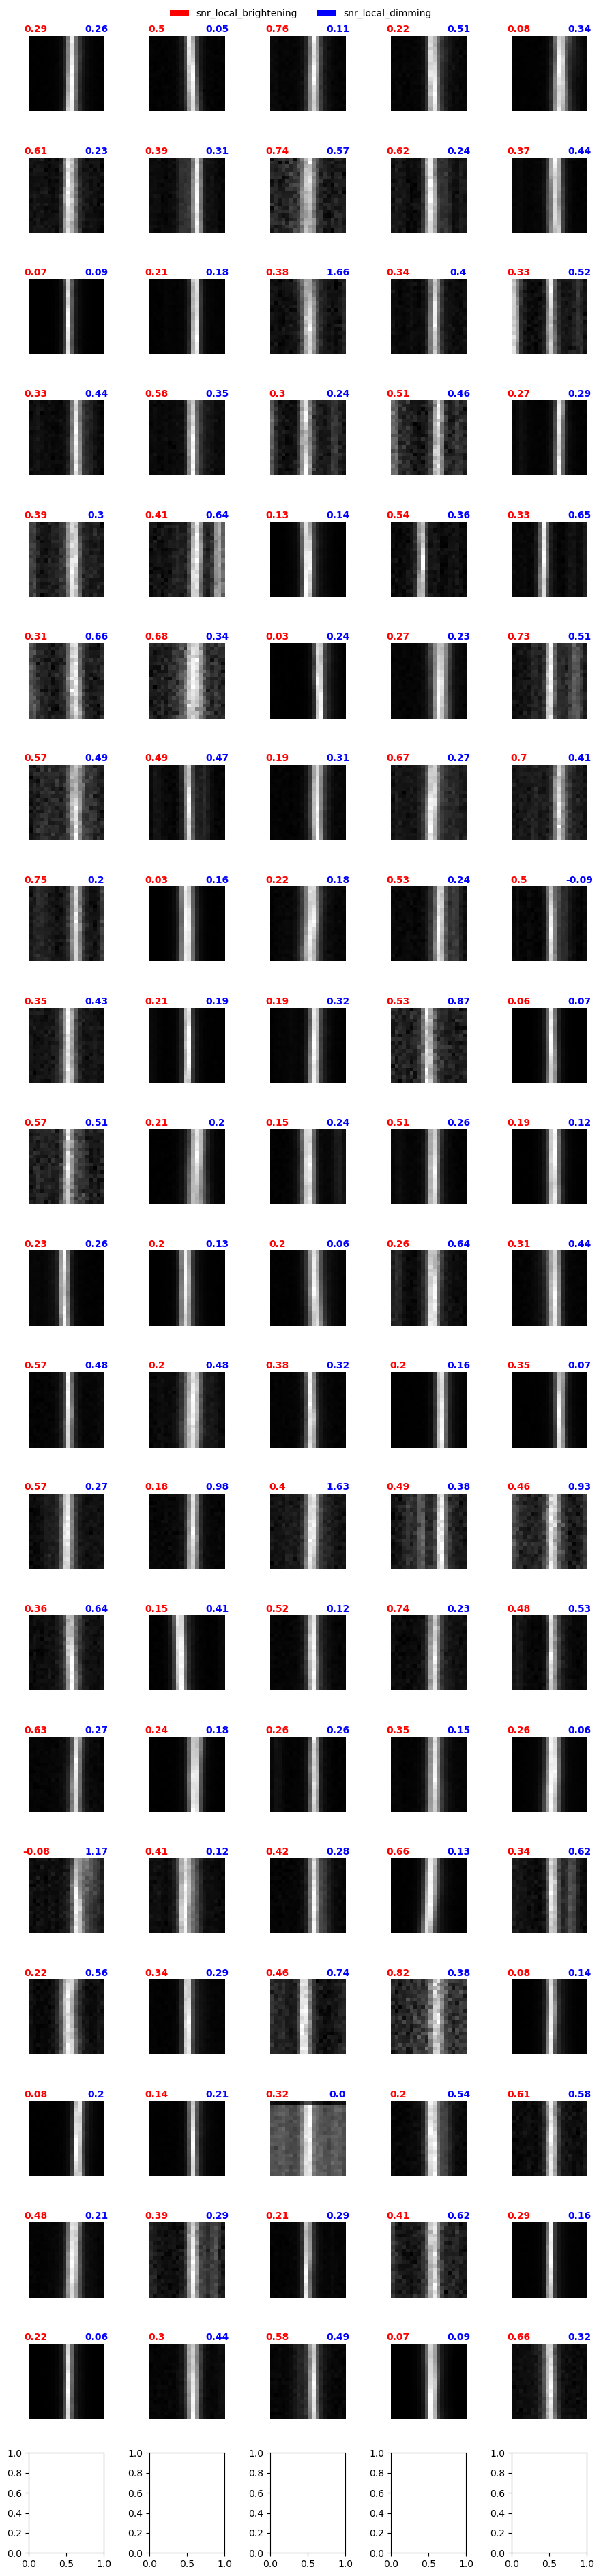

In [175]:
rff.inspect_df_w_stamp_color(lowsnrsample, plot_centers=False,star=False,titlecol=[ 'snr_local_brightening', 'snr_local_dimming'], twodec=True)

In [180]:
dim = concat[concat['snr_local_dimming']>2]

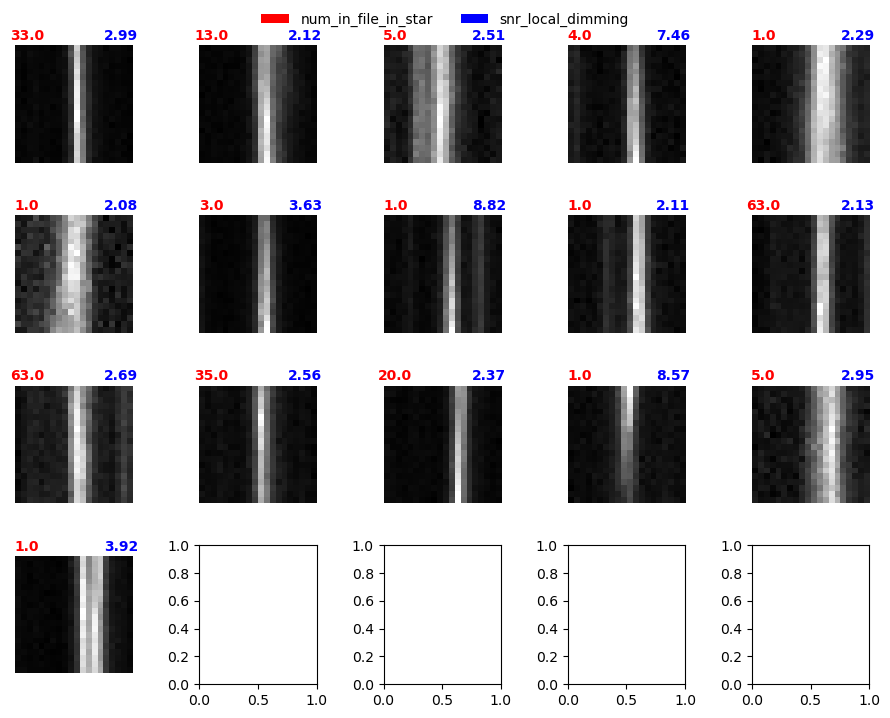

In [184]:

rff.inspect_df_w_stamp_color(dim, plot_centers=False,star=False,titlecol=[ 'num_in_file_in_star', 'snr_local_dimming'], twodec=True)

In [183]:
dim

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,...,snr_global_dimming,noise_local_dimming,noise_global_dimming,local_average_outside_dimming,height_dimming,FWHM_dimming,signal_local_dimming,central_point_dimming,quadrant,num_in_file_in_star
2587,2587,21,43,ztf_20221020141806_000686_zi_c14_x_0001.,1,pos,2394.363636,698.272727,11,708.0,...,1.720167,53.548647,93.062868,832.538788,-127.586029,108.0,160.083672,2399.0,1,33.0
5225,5225,8,26,ztf_20221020294271_000449_zr_c14_x_0001.,4,pos,1153.727273,914.909091,22,925.0,...,1.638408,37.025670,47.857005,1175.936435,-203.669528,33.0,78.409298,1156.0,4,13.0
7659,7659,215,150,ztf_20221020148032_000686_zg_c11_x_0029.,1,pos,1598.500000,2661.666667,6,2669.0,...,1.561878,34.001773,54.542223,620.928495,-114.447966,72.0,85.188293,1603.0,1,5.0
11417,11417,3,2,ztf_20221020141806_000686_zi_c01_x_0000.,1,both,39.971694,326.696219,182,337.0,...,7.132443,18.803764,19.669425,494.375380,-414.361982,45.0,140.291047,29.0,1,4.0
12427,12427,27,335,ztf_20221020148032_000686_zg_c04_x_0028.,2,pos,2611.000000,420.750000,8,432.0,...,1.678664,30.870734,42.047508,808.587653,-170.084967,34.0,70.583631,2627.0,2,1.0
14529,14529,0,224,ztf_20221020148032_000686_zg_c03_x_0028.,2,pos,3022.000000,142.500000,2,152.0,...,1.813086,13.045379,14.989863,260.953387,-61.811190,12.0,27.177910,3039.0,2,1.0
18641,18641,3,0,ztf_20221020141806_000686_zi_c01_x_0000.,2,pos,11.419580,112.517483,143,123.0,...,3.086603,32.070082,37.675741,1250.165779,-693.752449,20.0,116.290052,11.0,2,3.0
18657,18657,19,2,ztf_20221020141806_000686_zi_c01_x_0000.,2,pos,41.186207,1905.731034,145,1916.0,...,7.398592,18.444059,21.987278,673.847294,-385.853489,51.0,162.674904,42.0,2,1.0
21902,21902,1,0,ztf_20221020297847_000449_zr_c07_x_0000.,1,both,10.460784,1021.450980,38,1032.0,...,2.334702,18.455886,16.678624,503.959196,-233.516325,8.0,38.939614,2.0,1,1.0
22755,22755,18,15,ztf_20221020141806_000686_zi_c14_x_0001.,4,both,462.051724,696.870690,41,708.0,...,1.076833,53.027348,104.688455,560.916037,-200.147269,81.0,112.731958,455.0,4,63.0


In [189]:
#gonna check out the efficiency
pospath = ("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/df_both_matched_thr_0.99")
negpath = ("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/df_both_matched_thr_0.99")


In [190]:
pos = pd.read_csv(pospath)
neg = pd.read_csv(negpath)

In [191]:
pos

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,0,407,407,ztf_20221020138241_000686_zi_c05_x_0000.,1,both,65.148172,376.567536,116,387.0,...,1,1,10.0,[],0.0,14.378232,76.0,386.0,10.000,7.0
1,1,428,428,ztf_20221020138241_000686_zi_c05_x_0000.,1,both,1778.608366,376.554118,90,387.0,...,1,1,10.0,[],0.0,14.043175,1789.0,386.0,5.000,5.0
2,2,439,439,ztf_20221020138241_000686_zi_c05_x_0000.,1,both,2398.132824,376.343797,13,387.0,...,1,1,10.0,[440],0.0,13.805919,2408.0,386.0,7.000,3.0
3,3,406,406,ztf_20221020138241_000686_zi_c05_x_0000.,1,both,53.569920,548.845410,132,559.0,...,7,1,12.0,[],0.0,10.254795,55.0,559.0,5.000,9.0
4,4,414,414,ztf_20221020138241_000686_zi_c05_x_0000.,1,both,677.346154,548.860577,16,559.0,...,7,1,12.0,[416],0.0,14.000166,687.0,559.0,10.000,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
571,571,763,763,ztf_20221020294271_000449_zr_c04_x_0004.,4,both,433.000000,2910.000000,3,2917.0,...,0,4,11.0,[],0.0,221.110832,654.0,2917.0,1.300,3.0
572,572,765,765,ztf_20221020294271_000449_zr_c04_x_0004.,4,both,648.732639,2906.965278,48,2917.0,...,0,4,11.0,[],0.0,11.333170,654.0,2917.0,1.300,3.0
573,573,784,784,ztf_20221020294271_000449_zr_c04_x_0004.,4,both,1828.000000,2906.250000,1,2917.0,...,0,4,11.0,[785],1.0,20.113739,1811.0,2917.0,1.010,6.0
574,574,788,788,ztf_20221020294271_000449_zr_c04_x_0004.,4,both,2368.900000,2907.185714,70,2917.0,...,0,4,11.0,[],0.0,10.036444,2371.0,2917.0,1.500,9.0
